In [1]:
import sys
PATH_TO_PREDICTOR_HOME = ".."
sys.path.append(PATH_TO_PREDICTOR_HOME)


from mhcnames import normalize_allele_name
import numpy as np
import pandas as pd
from config import RESULT_COLUMNS


In [2]:
#DATA_PATH = "/home/denklewer/Data/gbm122/pVACseq/"
DATA_PATH = "D:/Google Drive/Work/ITMO/data/gbm122/pVACseq/"

In [3]:
from data_reading import read_gbm122_data

per_region_total_df , per_region_per_allele_mt_df, per_region_per_allele_wt_df = read_gbm122_data(DATA_PATH)


Region 1, unique (Transcrpit, Epitope pairs): 13197
found 5 alleles: ['HLA-A*03:01' 'HLA-B*35:01' 'HLA-B*40:01' 'HLA-C*03:04' 'HLA-C*04:01']
allele HLA-A*03:01: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
allele HLA-B*35:01: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
allele HLA-B*40:01: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
allele HLA-C*03:04: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
allele HLA-C*04:01: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
Region 2, unique (Transcrpit, Epitope pairs): 13273
found 5 alleles: ['HLA-A*03:01' 'HLA-B*35:01' 'HLA-B*40:01' 'HLA-C*03:04' 'HLA-C*04:01']
allele HLA-A*03:01: initial length 13279
take unique (MT_epitope, WT_epitope) pairs
result length 5127
allele HLA-B*35:01: initial length 13279
take unique (MT_epitope, WT_epitope) pairs
result length 51

D:\Tools\Python\Anaconda\envs\tf_env\lib\site-packages\IPython\core\interactiveshell.py:3347: DtypeWarning: Columns (10) have mixed types.Specify dtype option on import or set low_memory=False.
  if (await self.run_code(code, result,  async_=asy)):


Region 3, unique (Transcrpit, Epitope pairs): 15170
found 5 alleles: ['HLA-A*03:01' 'HLA-B*35:01' 'HLA-B*40:01' 'HLA-C*03:04' 'HLA-C*04:01']
allele HLA-A*03:01: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
allele HLA-B*35:01: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
allele HLA-B*40:01: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
allele HLA-C*03:04: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
allele HLA-C*04:01: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
Region 4, unique (Transcrpit, Epitope pairs): 13757
found 5 alleles: ['HLA-A*03:01' 'HLA-B*35:01' 'HLA-B*40:01' 'HLA-C*03:04' 'HLA-C*04:01']
allele HLA-A*03:01: initial length 13757
take unique (MT_epitope, WT_epitope) pairs
result length 4932
allele HLA-B*35:01: initial length 13757
take unique (MT_epitope, WT_epitope) pairs
result length 49

# 0. Preparations

In [4]:
sample_region_dict = next(iter(per_region_per_allele_wt_df.values()))
sample_allele_df =  next(iter(sample_region_dict.values()))

ALLELES = list(sample_region_dict.keys())
REGIONS = list(per_region_total_df.keys())
ALLELES, REGIONS

(['HLA-A*03:01', 'HLA-B*35:01', 'HLA-B*40:01', 'HLA-C*03:04', 'HLA-C*04:01'],
 [1, 2, 3, 4, 5])

# 1. Read all the predictions

In [5]:
per_method_columns = {
    'NetMHC': ['netMHC-3.4_score', 'netMHC-3.4_affinity', 'netMHC-4.0_score',  'netMHC-4.0_affinity','netMHC-4.0_percentile_rank', \
               'netMHCpan-4.1_score_ba', 'netMHCpan-4.1_score_el', 'netMHCpan-4.1_affinity', 'netMHCpan-4.1_percentile_rank_ba', 'netMHCpan-4.1_percentile_rank_el'  ],
    'netMHC-3.4': [ 'score', 'affinity', 'percentile_rank'],
    'netMHC-4.0':[ 'score', 'affinity', 'percentile_rank' ],
    'netMHCpan-4.1':[ 'score_ba', 'score_el', 'affinity', 'percentile_rank_ba', 'percentile_rank_el'],
    'mhcnuggets':[ 'score', 'affinity', 'percentile_rank'],
    'acme':['score'],
    'puffin':['score', 'epistemic_var', 'aleatoric_var', 'binding_likelihood'],
    'mhcseqnet':['score'],
    'mhcattnnet':[ 'score']
}
methods = ['NetMHC', 'puffin', 'mhcnuggets', 'acme', 'mhcseqnet', 'mhcattnnet']

In [6]:
PREDICTION_PATH = "D:/Google Drive/Work/ITMO/MHC-Epitop-Prediction/prediction_results/gbm122/"

per_region_per_allele_per_method_predictions = dict()

less_is_good_columns = {'affinity','percentile_rank', 'netMHC-3.4_affinity', 'netMHC-4.0_affinity', 
                                    'netMHCpan-4.1_affinity', 'netMHCpan-4.1_percentile_rank_ba', 
                                    'netMHCpan-4.1_percentile_rank_el', 'netMHC-4.0_percentile_rank', 'epistemic_var', 'aleatoric_var' }

for region in REGIONS:
    
    print(f"region {region}")
    per_region_per_allele_per_method_predictions[region] = dict()
    for allele_name in ALLELES:
        print(f"{allele_name}:", end=" ")
        per_region_per_allele_per_method_predictions[region][allele_name] = dict()
        for method in methods:
            target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
            prediction_df = pd.read_csv(f"{PREDICTION_PATH}{method}/{method}_predictions_reg_{region}_allele_{target_allele_name}.csv", sep=';')
            
            #add diff 
            
            print(f"{method}", end=" ")
            for score_column in per_method_columns[method]:
                result_score_column = f"{method}_{score_column}" if not (method == 'NetMHC') else score_column
                wt_scores = prediction_df[result_score_column + '_wt'].values
                mt_scores = prediction_df[result_score_column + '_mt'].values
                wt_peptide =  prediction_df['peptide_wt'].values
                # for these columns mt shoud be less than wt. In this case wt/mt will be > 1 and this is good. 
                if score_column in less_is_good_columns:
                    advantage = np.array([wt_sc/(mt_sc + 0.0000000001) if not peptide == np.nan else 2  for wt_sc,mt_sc, peptide in zip(wt_scores,mt_scores,wt_peptide)])
                # for these columns mt shoud be greater than wt. In this case mt/wt will be > 1 and this is good. 
                else:
                    advantage = np.array([mt_sc/(wt_sc + 0.0000000001) if not peptide == np.nan else 2  for wt_sc,mt_sc, peptide in zip(wt_scores,mt_scores,wt_peptide)])
                prediction_df[f"{result_score_column}_advantage"] = advantage
        
            
            
            per_region_per_allele_per_method_predictions[region][allele_name][method] = prediction_df
        print()
            

region 1
HLA-A*03:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*35:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*40:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*03:04: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*04:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
region 2
HLA-A*03:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*35:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*40:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*03:04: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*04:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
region 3
HLA-A*03:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*35:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*40:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*03:04: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*04:01: NetMHC puffin mhcnuggets acme mhcseqnet mhcattnnet

# 2. Merge predictions

In [7]:
per_region_per_allele_predictions = dict()
for region in REGIONS:
    per_region_per_allele_predictions[region] = dict()
    for allele_name in ALLELES:
        list_for_allele = list(per_region_per_allele_per_method_predictions[region][allele_name].values())
        
        result_df = list_for_allele[0].copy()
        for df_to_merge in list_for_allele[1:]:
            result_df = result_df.merge(df_to_merge, on=['source_sequence_name', 'peptide_mt', 'length', 'peptide_wt', 'allele'], how='left')
        result_df = result_df[['allele'] + [column for column in result_df.columns if column.endswith('mt')] 
                              + [column for column in result_df.columns if column.endswith('_advantage')] 
                              + [column for column in result_df.columns if column.endswith('wt')]] 
        per_region_per_allele_predictions[region][allele_name] = result_df
        

In [8]:
per_region_per_allele_per_method_predictions[region][allele_name][methods[0]]

,allele,length,peptide_mt,source_sequence_name,netMHC-3.4_score_mt,netMHC-3.4_affinity_mt,netMHC-3.4_percentile_rank_mt,netMHC-4.0_score_mt,netMHC-4.0_affinity_mt,netMHC-4.0_percentile_rank_mt,...,netMHC-3.4_score_advantage,netMHC-3.4_affinity_advantage,netMHC-4.0_score_advantage,netMHC-4.0_affinity_advantage,netMHC-4.0_percentile_rank_advantage,netMHCpan-4.1_score_ba_advantage,netMHCpan-4.1_score_el_advantage,netMHCpan-4.1_affinity_advantage,netMHCpan-4.1_percentile_rank_ba_advantage,netMHCpan-4.1_percentile_rank_el_advantage
0,HLA-C*04:01,8,TPRTRNKF,seq14936,0.227,4298.0,NaN,0.069,23721.15,16.0,...,1.392638,1.989065,1.725000,1.368788,1.812500,2.128395,17.113202,1.266190,2.397978,4.420019
1,HLA-C*04:01,8,SWPGAPVY,seq14939,0.281,2393.0,NaN,0.063,25206.14,17.0,...,1.200855,1.664020,1.032787,1.020837,1.058824,1.016023,0.819888,1.012872,1.042634,0.879405
2,HLA-C*04:01,8,YVAVCHPL,seq14940,0.158,9095.0,NaN,0.063,25338.76,18.0,...,1.153285,1.254755,1.235294,1.132415,1.222222,1.108490,2.204710,1.131031,1.384015,1.467259
3,HLA-C*04:01,8,RELLSLAF,seq14941,0.200,5765.0,NaN,0.060,26020.84,19.0,...,1.785714,2.595143,1.935484,1.375646,2.000000,0.977358,1.082393,0.983348,0.945173,1.039060
4,HLA-C*04:01,8,NQYASVAL,seq14942,0.198,5855.0,NaN,0.060,26063.96,19.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4942,HLA-C*04:01,11,LHGTLQKDGWT,seq65802,0.027,37202.0,NaN,0.009,45428.92,99.0,...,0.900000,0.970485,0.900000,0.983752,1.000000,0.944798,1.999800,0.991672,0.975732,1.055556
4943,HLA-C*04:01,11,SSSSSSSNNNY,seq65806,0.051,28654.0,NaN,0.009,45521.42,99.0,...,1.020000,1.015844,1.000000,1.001137,1.000000,1.087066,1.169117,1.021853,1.087430,1.062764
4944,HLA-C*04:01,11,RSSSSSSSSSN,seq65807,0.052,28604.0,NaN,0.009,45555.43,99.0,...,1.300000,1.128444,1.000000,1.000075,1.000000,0.993438,0.999950,0.999113,0.997598,1.000000
4945,HLA-C*04:01,11,SSSSSSSSSNN,seq65808,0.037,33371.0,NaN,0.008,45953.92,99.0,...,1.057143,1.030236,1.142857,1.008890,1.000000,1.026886,0.999900,1.002622,1.001346,1.000000


## Save total pred to file

In [9]:
#DATA_PATH = "/home/denklewer/Data/gbm122/" #ubuntu machine
DATA_PATH = "D:/Google Drive/Work/ITMO/MHC-Epitop-Prediction/prediction_results/gbm122/" # windows


In [10]:
# for decoy_key in DECOY_PREFIXES:

for region in REGIONS:
    for allele_name in ALLELES:
        total_df = per_region_per_allele_predictions[region][allele_name]
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        total_df.to_csv("{}total_predictions_reg_{}_allele_{}.csv".format(DATA_PATH,region,target_allele_name),sep=";", index=False)

In [11]:
per_region_per_allele_predictions[region][allele_name].columns

Index(['allele', 'peptide_mt', 'netMHC-3.4_score_mt', 'netMHC-3.4_affinity_mt',
       'netMHC-3.4_percentile_rank_mt', 'netMHC-4.0_score_mt',
       'netMHC-4.0_affinity_mt', 'netMHC-4.0_percentile_rank_mt',
       'netMHCpan-4.1_score_ba_mt', 'netMHCpan-4.1_score_el_mt',
       'netMHCpan-4.1_affinity_mt', 'netMHCpan-4.1_percentile_rank_ba_mt',
       'netMHCpan-4.1_percentile_rank_el_mt', 'puffin_score_mt',
       'puffin_epistemic_var_mt', 'puffin_aleatoric_var_mt',
       'puffin_binding_likelihood_mt', 'mhcnuggets_score_mt',
       'mhcnuggets_affinity_mt', 'mhcnuggets_percentile_rank_mt',
       'acme_score_mt', 'mhcseqnet_score_mt', 'mhcattnnet_score_mt',
       'netMHC-3.4_score_advantage', 'netMHC-3.4_affinity_advantage',
       'netMHC-4.0_score_advantage', 'netMHC-4.0_affinity_advantage',
       'netMHC-4.0_percentile_rank_advantage',
       'netMHCpan-4.1_score_ba_advantage', 'netMHCpan-4.1_score_el_advantage',
       'netMHCpan-4.1_affinity_advantage',
       'netMHCpan-4

<AxesSubplot:>

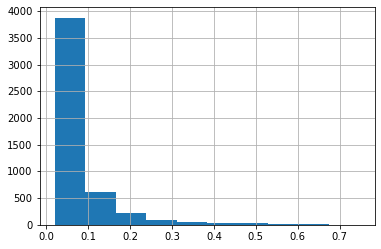

In [12]:
per_region_per_allele_predictions[region][ALLELES[0]]['puffin_score_mt'].hist()

In [13]:

def filter_epitopes(df, method_name, advantage = False):
    if method_name == 'netMHC-3.4':
        df = df.loc[df[method_name + "_affinity_mt"] < 500].copy()
        if advantage:
            df = df.loc[df[method_name + "_score_advantage"] > 1].copy()
    elif  method_name == 'netMHC-4.0':
        df = df.loc[df[method_name +  "_percentile_rank_mt"] < 2].copy()
        if advantage:
            df = df.loc[df[method_name + "_percentile_rank_advantage"] > 1].copy()
    elif method_name == 'netMHCpan-4.1':
        df = df.loc[df[method_name + "_percentile_rank_el_mt"] < 2].copy()
        if advantage:
            df = df.loc[df[method_name + "_percentile_rank_el_advantage"] > 1].copy()
    elif method_name == 'mhcnuggets':
        df = df.loc[df[method_name + "_percentile_rank_mt"] < 2].copy()
        if advantage:
            df = df.loc[df[method_name + "_percentile_rank_advantage"] > 1].copy()
    elif method_name == 'acme':
        df = df.loc[df[method_name + "_score_mt"] > 0.42].copy()
        if advantage:
            df = df.loc[df[method_name + "_score_advantage"] > 1].copy()
    elif method_name == 'mhcseqnet':
        df = df.loc[df[method_name + "_score_mt"] > 0.99].copy()
        if advantage:
            df = df.loc[df[method_name + "_score_advantage"] > 1].copy()
    elif method_name == 'puffin':
        df = df.loc[df[method_name + "_score_mt"] > 0.42].copy()
        if advantage:
            df = df.loc[df[method_name + "_score_advantage"] > 1].copy()
    elif method_name == 'mhcattnnet':
        df = df.loc[df[method_name + "_score_mt"] >= 1].copy()
        if advantage:
            df = df.loc[df[method_name + "_score_advantage"] > 1].copy()
    return df


# 3. Get top epitopes

In [14]:
methods = ['netMHC-3.4', 'netMHC-4.0', 'netMHCpan-4.1', 'puffin', 'mhcnuggets', 'acme', 'mhcseqnet', 'mhcattnnet']
per_region_per_allele_per_method_top_epitopes = dict()
for region in REGIONS:
    per_region_per_allele_per_method_top_epitopes[region] = dict()
    print(f"region {region}")
    for allele_name in ALLELES:
        per_region_per_allele_per_method_top_epitopes[region][allele_name] = dict()
        print(f"{allele_name}:", end=" ")
        for method in methods:
            print(f"{method}", end=" ")
            prediction_df = per_region_per_allele_predictions[region][allele_name]
            per_region_per_allele_per_method_top_epitopes[region][allele_name][method] = filter_epitopes(prediction_df, method)

            
#             for score_column in per_method_columns[method]:
#                 result_score_column = f"{method}_{score_column}" if not (method == 'NetMHC') else score_column
#                 wt_scores = prediction_df[result_score_column + '_wt'].values
#                 mt_scores = prediction_df[result_score_column + '_mt'].values
#                 wt_peptide =  prediction_df['peptide_wt'].values
#                 # for these columns mt shoud be less than wt. In this case wt/mt will be > 1 and this is good. 
#                 if score_column in ['affinity','percentile_rank', 'netMHC-3.4_affinity', 'netMHC-4.0_affinity', 'netMHCpan-4.1_affinity', 'percentile_rank_ba', 'percentile_rank_el' ]:
#                     advantage = np.array([wt_sc/(mt_sc + 0.0000000001) if not peptide == np.nan else 2  for wt_sc,mt_sc, peptide in zip(wt_scores,mt_scores,wt_peptide)])
#                 # for these columns mt shoud be greater than wt. In this case mt/wt will be > 1 and this is good. 
#                 else:
#                     advantage = np.array([mt_sc/(wt_sc + 0.0000000001) if not peptide == np.nan else 2  for wt_sc,mt_sc, peptide in zip(wt_scores,mt_scores,wt_peptide)])
#                 prediction_df[f"{result_score_column}_advantage"] = advantage
        
        print()
            

region 1
HLA-A*03:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*35:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*40:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*03:04: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*04:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
region 2
HLA-A*03:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*35:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*40:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*03:04: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*04:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
region 3
HLA-A*03:01: netMHC-3.4 netMHC-4.

In [15]:
per_region_per_allele_per_method_top_epitopes[1][ALLELES[0]]['mhcnuggets']

,allele,peptide_mt,netMHC-3.4_score_mt,netMHC-3.4_affinity_mt,netMHC-3.4_percentile_rank_mt,netMHC-4.0_score_mt,netMHC-4.0_affinity_mt,netMHC-4.0_percentile_rank_mt,netMHCpan-4.1_score_ba_mt,netMHCpan-4.1_score_el_mt,...,puffin_score_wt,puffin_epistemic_var_wt,puffin_aleatoric_var_wt,puffin_binding_likelihood_wt,mhcnuggets_score_wt,mhcnuggets_affinity_wt,mhcnuggets_percentile_rank_wt,acme_score_wt,mhcseqnet_score_wt,mhcattnnet_score_wt
1,HLA-A*03:01,SILDTVLK,0.534,154.0,NaN,0.269,2723.52,3.50,0.270773,0.107500,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.00025,NaN,NaN,NaN
6,HLA-A*03:01,AVCHPLHY,0.351,1125.0,NaN,0.163,8560.84,7.50,0.159600,0.039726,...,0.279112,0.008548,0.038501,0.216767,0.217696,4742.66,0.74425,0.367504,0.986015,0.999554
10,HLA-A*03:01,ILDTVLKY,0.352,1105.0,NaN,0.146,10355.16,9.00,0.136256,0.025784,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.00025,NaN,NaN,NaN
38,HLA-A*03:01,QVFPHLSL,0.121,13459.0,NaN,0.072,23050.42,23.00,0.078567,0.002521,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.00025,NaN,NaN,NaN
465,HLA-A*03:01,KLLMRDPHK,0.653,42.0,NaN,0.650,44.25,0.25,0.649539,0.735985,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.00025,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5171,HLA-A*03:01,GILGNFSLLLY,0.484,265.0,NaN,0.354,1081.53,2.50,0.332757,0.065159,...,0.517685,0.003200,0.044579,0.651856,0.379061,827.51,0.06075,0.510594,0.999163,0.962453
5174,HLA-A*03:01,ILGNFSLLLYV,0.162,8622.0,NaN,0.302,1897.23,3.00,0.207174,0.001003,...,0.501977,0.007374,0.045483,0.616078,0.225166,4374.42,0.57325,0.466016,0.957072,0.384617
5182,HLA-A*03:01,TMYFLLSILSL,0.293,2095.0,NaN,0.159,8947.03,8.00,0.134422,0.000338,...,0.190049,0.001492,0.022791,0.084874,0.203693,5518.51,2.88475,0.054261,0.022160,0.999994
5192,HLA-A*03:01,SISPSERSYRL,0.093,18259.0,NaN,0.114,14595.46,13.00,0.113731,0.002970,...,0.045826,0.000132,0.004269,0.000619,0.201861,5629.00,35.58075,0.161645,0.905520,0.999998


# 4 Save top epitopes

In [16]:
#DATA_PATH = "/home/denklewer/Data/gbm122/" #ubuntu machine
DATA_PATH = "D:/Google Drive/Work/ITMO/MHC-Epitop-Prediction/prediction_results/gbm122/" # windows


In [17]:
# for decoy_key in DECOY_PREFIXES:
import os
# if not os.path.exists(TARGET_PATH_TO_PREDICTIONS):
#     os.makedirs(TARGET_PATH_TO_PREDICTIONS)
    
for region in REGIONS:
    for allele_name in ALLELES:
        for method in methods:
            if method.startswith('netMHC'):
                TARGET_PATH_TO_PREDICTIONS = DATA_PATH + 'NetMHC/{}/'.format(method)
            else:
                TARGET_PATH_TO_PREDICTIONS = DATA_PATH + '{}/'.format(method)
            if not os.path.exists(TARGET_PATH_TO_PREDICTIONS):
                os.makedirs(TARGET_PATH_TO_PREDICTIONS)
            TARGET_PATH_TOP_EPITOPES = TARGET_PATH_TO_PREDICTIONS + 'top_epitopes/threshold/'
            if not os.path.exists(TARGET_PATH_TOP_EPITOPES):
                os.makedirs(TARGET_PATH_TOP_EPITOPES)

            total_df = per_region_per_allele_per_method_top_epitopes[region][allele_name][method]
            target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
            total_df.to_csv("{}{}_top_epitopes_all_reg_{}_allele_{}.csv".format(TARGET_PATH_TOP_EPITOPES, method,region,target_allele_name),sep=";", index=False)


# 3. Get top epitopes with advantage

In [18]:
methods = ['netMHC-3.4', 'netMHC-4.0', 'netMHCpan-4.1', 'puffin', 'mhcnuggets', 'acme', 'mhcseqnet', 'mhcattnnet']
per_region_per_allele_per_method_top_epitopes = dict()
for region in REGIONS:
    per_region_per_allele_per_method_top_epitopes[region] = dict()
    print(f"region {region}")
    for allele_name in ALLELES:
        per_region_per_allele_per_method_top_epitopes[region][allele_name] = dict()
        print(f"{allele_name}:", end=" ")
        for method in methods:
            print(f"{method}", end=" ")
            prediction_df = per_region_per_allele_predictions[region][allele_name]
            per_region_per_allele_per_method_top_epitopes[region][allele_name][method] = filter_epitopes(prediction_df, method, advantage=True)

            
#             for score_column in per_method_columns[method]:
#                 result_score_column = f"{method}_{score_column}" if not (method == 'NetMHC') else score_column
#                 wt_scores = prediction_df[result_score_column + '_wt'].values
#                 mt_scores = prediction_df[result_score_column + '_mt'].values
#                 wt_peptide =  prediction_df['peptide_wt'].values
#                 # for these columns mt shoud be less than wt. In this case wt/mt will be > 1 and this is good. 
#                 if score_column in ['affinity','percentile_rank', 'netMHC-3.4_affinity', 'netMHC-4.0_affinity', 'netMHCpan-4.1_affinity', 'percentile_rank_ba', 'percentile_rank_el' ]:
#                     advantage = np.array([wt_sc/(mt_sc + 0.0000000001) if not peptide == np.nan else 2  for wt_sc,mt_sc, peptide in zip(wt_scores,mt_scores,wt_peptide)])
#                 # for these columns mt shoud be greater than wt. In this case mt/wt will be > 1 and this is good. 
#                 else:
#                     advantage = np.array([mt_sc/(wt_sc + 0.0000000001) if not peptide == np.nan else 2  for wt_sc,mt_sc, peptide in zip(wt_scores,mt_scores,wt_peptide)])
#                 prediction_df[f"{result_score_column}_advantage"] = advantage
        
        print()
            

region 1
HLA-A*03:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*35:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*40:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*03:04: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*04:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
region 2
HLA-A*03:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*35:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-B*40:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*03:04: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
HLA-C*04:01: netMHC-3.4 netMHC-4.0 netMHCpan-4.1 puffin mhcnuggets acme mhcseqnet mhcattnnet 
region 3
HLA-A*03:01: netMHC-3.4 netMHC-4.

In [19]:
per_region_per_allele_per_method_top_epitopes[1][ALLELES[0]]['mhcnuggets']

,allele,peptide_mt,netMHC-3.4_score_mt,netMHC-3.4_affinity_mt,netMHC-3.4_percentile_rank_mt,netMHC-4.0_score_mt,netMHC-4.0_affinity_mt,netMHC-4.0_percentile_rank_mt,netMHCpan-4.1_score_ba_mt,netMHCpan-4.1_score_el_mt,...,puffin_score_wt,puffin_epistemic_var_wt,puffin_aleatoric_var_wt,puffin_binding_likelihood_wt,mhcnuggets_score_wt,mhcnuggets_affinity_wt,mhcnuggets_percentile_rank_wt,acme_score_wt,mhcseqnet_score_wt,mhcattnnet_score_wt
6,HLA-A*03:01,AVCHPLHY,0.351,1125.0,NaN,0.163,8560.84,7.50,0.159600,0.039726,...,0.279112,0.008548,0.038501,0.216767,0.217696,4742.66,0.74425,0.367504,0.986015,0.999554
466,HLA-A*03:01,GAFYVWGSK,0.532,158.0,NaN,0.558,119.72,0.50,0.516542,0.222574,...,0.477844,0.004049,0.045332,0.580909,0.205738,5397.73,1.77875,0.612409,0.967016,0.999806
469,HLA-A*03:01,SLNNTWLNR,0.526,169.0,NaN,0.527,166.96,0.70,0.499222,0.597556,...,0.308036,0.005867,0.037816,0.248949,0.234610,3949.53,0.46575,0.296434,0.267321,0.999975
470,HLA-A*03:01,VAAEIFLKK,0.568,106.0,NaN,0.507,207.84,0.80,0.515243,0.731245,...,0.076028,0.000173,0.004324,0.000252,0.202209,5607.83,13.60775,0.075235,0.566792,0.996626
477,HLA-A*03:01,SLGWIRTRR,0.378,832.0,NaN,0.393,712.64,1.60,0.388432,0.178344,...,0.343937,0.002391,0.039102,0.322964,0.202577,5585.56,6.42425,0.317950,0.762726,0.999902
480,HLA-A*03:01,MVHLGVVLY,0.455,362.0,NaN,0.382,800.29,1.70,0.371971,0.198516,...,0.192008,0.002263,0.023799,0.081924,0.201185,5670.31,89.62150,0.222358,0.086553,0.010901
482,HLA-A*03:01,GIREGFSFH,0.359,1029.0,NaN,0.319,1586.09,2.50,0.317363,0.163786,...,0.148783,0.001167,0.016729,0.030728,0.203026,5558.47,4.03650,0.154352,0.072134,0.009838
483,HLA-A*03:01,RIPPGTQNY,0.286,2257.0,NaN,0.298,1988.29,3.00,0.229158,0.332929,...,0.196477,0.003129,0.023689,0.081174,0.204295,5482.69,2.39125,0.101940,0.153972,0.287101
485,HLA-A*03:01,ASLGWIRTR,0.215,4863.0,NaN,0.258,3078.88,4.00,0.339926,0.367624,...,0.293039,0.005916,0.035623,0.237084,0.210228,5141.77,1.11375,0.205353,0.610678,0.996209
514,HLA-A*03:01,LTFVWKLVV,0.105,16133.0,NaN,0.137,11304.75,9.50,0.136830,0.001059,...,0.158769,0.001200,0.016872,0.033185,0.202475,5591.75,7.56900,0.157833,0.114908,0.910931


# 4 Save top epitopes

In [20]:
#DATA_PATH = "/home/denklewer/Data/gbm122/" #ubuntu machine
DATA_PATH = "D:/Google Drive/Work/ITMO/MHC-Epitop-Prediction/prediction_results/gbm122/" # windows


In [21]:
# for decoy_key in DECOY_PREFIXES:

for region in REGIONS:
    for allele_name in ALLELES:
        for method in methods:
            if method.startswith('netMHC'):
                TARGET_PATH_TO_PREDICTIONS = DATA_PATH + 'NetMHC/{}/'.format(method)
            else:
                TARGET_PATH_TO_PREDICTIONS = DATA_PATH + '{}/'.format(method)
            TARGET_PATH_TOP_EPITOPES = TARGET_PATH_TO_PREDICTIONS + 'top_epitopes/threshold+advantage/'
            if not os.path.exists(TARGET_PATH_TOP_EPITOPES):
                os.makedirs(TARGET_PATH_TOP_EPITOPES)

            total_df = per_region_per_allele_per_method_top_epitopes[region][allele_name][method]
            target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
            total_df.to_csv("{}{}_top_epitopes_advantage_reg_{}_allele_{}.csv".format(TARGET_PATH_TOP_EPITOPES, method,region,target_allele_name),sep=";", index=False)